# ЛР05. Запуск открытой text-to-image модели

**Вариант 7:** бриф №2 — обложка подкаста о городской среде; условие `repeat`; seed 1007.

## Гипотеза и допуск — зафиксированы до запуска

**Гипотеза.** При неизменной среде, одинаковых параметрах, seed 1007 и свежем CPU-генераторе для каждого вызова изображения A и B совпадут побитово.

**Допуск.** `identical` — при побитовом совпадении; `close` — при несовпадении пикселей и PSNR ≥ 40 дБ; `different` — при PSNR < 40 дБ.

Вывод будет сделан только после фактического измерения. Совпадение внутри одного сеанса не доказывает совпадение на другой машине.

In [2]:
# Проверка GPU и фактических версий. Не продолжайте без CUDA.
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip list 2>/dev/null | grep -i -E "^(torch|diffusers|transformers|pillow) "

import json, pathlib, platform, sys, time
import torch, diffusers, transformers, PIL

assert torch.cuda.is_available(), "CUDA GPU недоступен: выберите GPU в настройках Colab"
environment = {
    "execution_environment": "Google Colab",
    "gpu": torch.cuda.get_device_name(0),
    "cuda_available": torch.cuda.is_available(),
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "packages": {
        "torch": torch.__version__,
        "diffusers": diffusers.__version__,
        "transformers": transformers.__version__,
        "pillow": PIL.__version__,
    },
}
print(json.dumps(environment, ensure_ascii=False, indent=2))

name, memory.total [MiB]
Tesla T4, 15360 MiB
diffusers                             0.41.0
pillow                                11.3.0
torch                                 2.11.0+cu130
transformers                          5.20.1
{
  "execution_environment": "Google Colab",
  "gpu": "Tesla T4",
  "cuda_available": true,
  "python": "3.13.15",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "packages": {
    "torch": "2.11.0+cu130",
    "diffusers": "0.41.0",
    "transformers": "5.20.1",
    "pillow": "11.3.0"
  }
}


In [3]:
%%writefile lab05_lib.py
# ЛР 5. Запуск открытой модели text-to-image. Библиотека учебных функций.
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128, diffusers 0.40.0, transformers 5.16.1.
# Модель: stabilityai/sd-turbo, ревизия закреплена (см. REVISION). Веса загружаются с Hugging Face без авторизации.
import hashlib, io, time
import numpy as np
import torch
from PIL import Image
from diffusers import AutoPipelineForText2Image
from diffusers.utils import logging as dlog

dlog.set_verbosity_error()  # убирает предупреждения о приведении типов при pipe.to(dtype)

MODEL_ID = "stabilityai/sd-turbo"
REVISION = "b261bac6fd2cf515557d5d0707481eafa0485ec2"

# Пять контекстов (брифов). Во всех запретены текст, логотипы и люди.
BRIEFS = [
    "editorial poster concept for a robotics festival, glowing mechanical arm silhouette, deep blue and amber palette, clean composition, no text, no logo, no people",
    "square podcast cover about the city environment, abstract layered skyline of geometric shapes, teal and orange palette, minimal flat style, no text, no people",
    "poster concept for a science exhibition, abstract constellation of connected nodes, dark background with white and cyan lines, balanced composition, no text, no logo",
    "visual for an ecology lecture series, stylized forest canopy seen from above, layered green shapes, soft morning light, no text, no people",
    "cover art for an electronic music release, brushed metal surface with iridescent reflections, macro photography style, strong contrast, no text, no logo, no people",
]


def load_pipe(dtype=torch.float16):
    """Загружает закреплённую ревизию (файлы fp16) на GPU; dtype задаёт тип вычислений."""
    pipe = AutoPipelineForText2Image.from_pretrained(
        MODEL_ID, revision=REVISION, torch_dtype=torch.float16, variant="fp16", use_safetensors=True)
    pipe.set_progress_bar_config(disable=True)
    return pipe.to("cuda", dtype)


def generate(pipe, prompt, seed, steps=1, guidance=0.0, size=512, batch=1, gen_device="cpu"):
    """Возвращает список PIL-изображений. Для каждого элемента пакета свой генератор: seed, seed+1, ..."""
    gens = [torch.Generator(device=gen_device).manual_seed(seed + i) for i in range(batch)]
    return pipe(prompt=[prompt] * batch, num_inference_steps=steps, guidance_scale=guidance,
                height=size, width=size, generator=gens).images


def generate_fixed_noise(pipe, prompt, seed, steps=1, guidance=0.0, size=512):
    """Начальный шум всегда строится в float32 и приводится к типу вычислений: так меняется только точность."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    lat = torch.randn((1, 4, size // 8, size // 8), generator=g, dtype=torch.float32).to("cuda", pipe.unet.dtype)
    return pipe(prompt=[prompt], num_inference_steps=steps, guidance_scale=guidance, height=size, width=size, latents=lat).images[0]


def png_bytes(img):
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    return buf.getvalue()


def sha(data):
    return hashlib.sha256(data).hexdigest()


def to_arr(img):
    return np.asarray(img.convert("RGB"), dtype=np.float64)


def psnr_db(a, b):
    """PSNR для значений 0..255; inf, если изображения совпадают."""
    mse = np.mean((to_arr(a) - to_arr(b)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)


def max_abs_diff(a, b):
    return int(np.max(np.abs(to_arr(a) - to_arr(b))))


def jpeg_roundtrip(img, quality=90):
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=quality)
    buf.seek(0)
    return Image.open(buf).convert("RGB"), buf.getvalue()


def classify(psnr, tol_db=40.0):
    """Классификация пары по допуску, заданному до эксперимента."""
    return "identical" if psnr == float("inf") else ("close" if psnr >= tol_db else "different")


# Шесть условий сравнения (фактор варианта). Каждое условие даёт пару изображений A и B.
CONDITIONS = ["repeat", "seed_plus_1", "generator_device", "dtype", "file_format", "batch"]


def make_pair(pipe, prompt, seed, cond):
    if cond == "repeat":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed)[0]
    elif cond == "seed_plus_1":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed + 1)[0]
    elif cond == "generator_device":
        a = generate(pipe, prompt, seed, gen_device="cpu")[0]; b = generate(pipe, prompt, seed, gen_device="cuda")[0]
    elif cond == "dtype":
        pipe.to(torch.float16); a = generate(pipe, prompt, seed)[0]
        pipe.to(torch.float32); b = generate(pipe, prompt, seed)[0]
        pipe.to(torch.float16)
    elif cond == "file_format":
        a = generate(pipe, prompt, seed)[0]; b, _ = jpeg_roundtrip(a, 90)
    elif cond == "batch":
        a = generate(pipe, prompt, seed)[0]; b = generate(pipe, prompt, seed, batch=4)[0]
    else:
        raise ValueError(cond)
    return a, b


def variant_summary(pipe, n):
    """Вариант n = 1..30: контекст c = (n-1)//6 + 1, условие k = (n-1)%6 + 1."""
    c, k = (n - 1) // 6, (n - 1) % 6
    seed = 1000 + n
    t0 = time.perf_counter()
    a, b = make_pair(pipe, BRIEFS[c], seed, CONDITIONS[k])
    dt = time.perf_counter() - t0
    p = psnr_db(a, b)
    pf = None
    if CONDITIONS[k] == "dtype":  # проверка причины: одинаковый начальный шум в обоих режимах
        pipe.to(torch.float16); fa = generate_fixed_noise(pipe, BRIEFS[c], seed)
        pipe.to(torch.float32); fb = generate_fixed_noise(pipe, BRIEFS[c], seed)
        pipe.to(torch.float16); pf = psnr_db(fa, fb)
    return dict(variant=n, ctx=c + 1, cond=CONDITIONS[k], seed=seed, sha_a=sha(png_bytes(a)), sha_b=sha(png_bytes(b)),
                pixel_equal=bool(np.array_equal(to_arr(a), to_arr(b))), max_diff=max_abs_diff(a, b), psnr=p,
                verdict=classify(p), seconds=round(dt, 2), psnr_fixed_noise=pf)


Overwriting lab05_lib.py


In [4]:
# Фиксированные параметры варианта.
import hashlib, math
from datetime import datetime, timezone
import numpy as np
import pandas as pd
from IPython.display import display
import lab05_lib as L

VARIANT = 7
BRIEF = 2
CONDITION = "repeat"
SEED = 1007
STEPS = 1
GUIDANCE = 0.0
SIZE = 512
TOLERANCE_DB = 40.0
PROMPT = L.BRIEFS[BRIEF - 1]

assert L.MODEL_ID == "stabilityai/sd-turbo"
assert L.REVISION == "b261bac6fd2cf515557d5d0707481eafa0485ec2"
assert L.CONDITIONS[(VARIANT - 1) % 6] == CONDITION
assert 1000 + VARIANT == SEED

root = pathlib.Path('.')
artifacts = root / "artifacts"
reports = root / "reports"
for path in [artifacts / "run_001", artifacts / "pair_A", artifacts / "pair_B", reports]:
    path.mkdir(parents=True, exist_ok=True)

library_sha256 = hashlib.sha256(pathlib.Path("lab05_lib.py").read_bytes()).hexdigest()
print({"prompt": PROMPT, "library_sha256": library_sha256})

{'prompt': 'square podcast cover about the city environment, abstract layered skyline of geometric shapes, teal and orange palette, minimal flat style, no text, no people', 'library_sha256': '4eb176506585ffcda1702605a767309fb451808229c3622f80ce882b7fa2ce1a'}


In [5]:
# Загрузка закреплённой ревизии и прогрев.
load_started = time.perf_counter()
pipe = L.load_pipe()
load_seconds = time.perf_counter() - load_started

warmup_started = time.perf_counter()
_ = L.generate(pipe, PROMPT, 1)[0]
warmup_seconds = time.perf_counter() - warmup_started
print({"load_seconds": round(load_seconds, 2), "warmup_seconds": round(warmup_seconds, 2)})

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

{'load_seconds': 26.77, 'warmup_seconds': 5.62}


{
  "model_id": "stabilityai/sd-turbo",
  "revision": "b261bac6fd2cf515557d5d0707481eafa0485ec2",
  "prompt": "square podcast cover about the city environment, abstract layered skyline of geometric shapes, teal and orange palette, minimal flat style, no text, no people",
  "variant": 7,
  "brief": 2,
  "condition": "repeat",
  "seed": 1007,
  "steps": 1,
  "guidance_scale": 0.0,
  "size": 512,
  "generator_device": "cpu",
  "dtype": "float16",
  "device": "Tesla T4",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "python": "3.13.15",
  "packages": {
    "torch": "2.11.0+cu130",
    "diffusers": "0.41.0",
    "transformers": "5.20.1",
    "pillow": "11.3.0"
  },
  "load_seconds": 26.77,
  "warmup_seconds": 5.62,
  "generation_seconds": 0.36,
  "image_size": [
    512,
    512
  ],
  "image_mode": "RGB",
  "sha256": "96b809ceb59215db2a042f58ec1bdf68d336f5b6797a415f70790495fadb6efb",
  "library_sha256": "4eb176506585ffcda1702605a767309fb451808229c3622f80ce882b7fa2ce1a",
  "execut

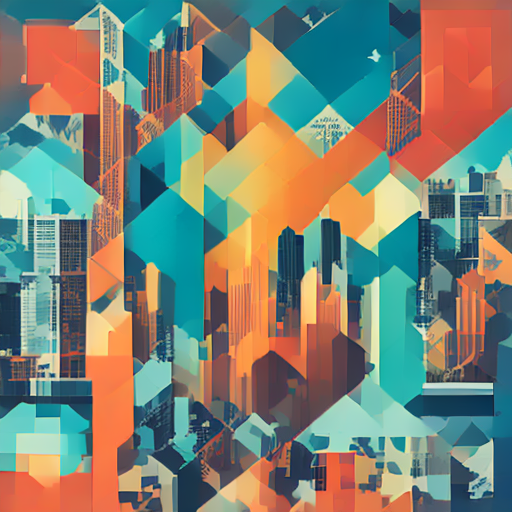

In [6]:
# Базовый запуск: artifacts/run_001/result.png и manifest.json.
generation_started = time.perf_counter()
baseline = L.generate(pipe, PROMPT, SEED, STEPS, GUIDANCE, SIZE)[0]
generation_seconds = time.perf_counter() - generation_started
baseline_bytes = L.png_bytes(baseline)
baseline_sha256 = L.sha(baseline_bytes)
(artifacts / "run_001" / "result.png").write_bytes(baseline_bytes)

manifest = {
    "model_id": L.MODEL_ID,
    "revision": L.REVISION,
    "prompt": PROMPT,
    "variant": VARIANT,
    "brief": BRIEF,
    "condition": CONDITION,
    "seed": SEED,
    "steps": STEPS,
    "guidance_scale": GUIDANCE,
    "size": SIZE,
    "generator_device": "cpu",
    "dtype": "float16",
    "device": environment["gpu"],
    "platform": environment["platform"],
    "python": environment["python"],
    "packages": environment["packages"],
    "load_seconds": round(load_seconds, 2),
    "warmup_seconds": round(warmup_seconds, 2),
    "generation_seconds": round(generation_seconds, 2),
    "image_size": list(baseline.size),
    "image_mode": baseline.mode,
    "sha256": baseline_sha256,
    "library_sha256": library_sha256,
    "executed_at_utc": datetime.now(timezone.utc).isoformat(),
}
(artifacts / "run_001" / "manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
print(json.dumps(manifest, ensure_ascii=False, indent=2))
display(baseline)

In [7]:
# Пара A/B для repeat: каждый вызов L.generate создаёт свежий CPU-Generator.
pair_started = time.perf_counter()
image_a, image_b = L.make_pair(pipe, PROMPT, SEED, CONDITION)
pair_seconds = time.perf_counter() - pair_started
bytes_a, bytes_b = L.png_bytes(image_a), L.png_bytes(image_b)
sha_a, sha_b = L.sha(bytes_a), L.sha(bytes_b)
pixel_equal = bool(np.array_equal(L.to_arr(image_a), L.to_arr(image_b)))
max_diff = L.max_abs_diff(image_a, image_b)
psnr = L.psnr_db(image_a, image_b)
verdict = L.classify(psnr, TOLERANCE_DB)
psnr_json = "inf" if math.isinf(psnr) else float(psnr)

(artifacts / "pair_A" / "result.png").write_bytes(bytes_a)
(artifacts / "pair_B" / "result.png").write_bytes(bytes_b)

def pair_manifest(label, image, digest):
    return {
        "label": label, "model_id": L.MODEL_ID, "revision": L.REVISION,
        "prompt": PROMPT, "variant": VARIANT, "brief": BRIEF,
        "condition": CONDITION, "seed": SEED, "steps": STEPS,
        "guidance_scale": GUIDANCE, "size": SIZE,
        "generator_device": "cpu", "generator_fresh": True,
        "dtype": "float16", "device": environment["gpu"],
        "platform": environment["platform"], "python": environment["python"],
        "packages": environment["packages"], "image_size": list(image.size),
        "image_mode": image.mode, "sha256": digest,
        "library_sha256": library_sha256,
    }

manifest_a = pair_manifest("A", image_a, sha_a)
manifest_b = pair_manifest("B", image_b, sha_b)
for label, data in [("pair_A", manifest_a), ("pair_B", manifest_b)]:
    (artifacts / label / "manifest.json").write_text(
        json.dumps(data, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")

comparison = {
    "variant": VARIANT, "condition": CONDITION, "seed": SEED,
    "sha256_a": sha_a, "sha256_b": sha_b,
    "pixel_equal": pixel_equal, "max_diff": max_diff,
    "psnr_db": psnr_json, "tolerance_db": TOLERANCE_DB,
    "verdict": verdict, "pair_seconds": round(pair_seconds, 2),
}
(artifacts / "comparison.json").write_text(
    json.dumps(comparison, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")

comparison_table = pd.DataFrame([{
    "SHA-256 A": sha_a, "SHA-256 B": sha_b,
    "pixel_equal": pixel_equal, "max_diff": max_diff,
    "PSNR, dB": '∞' if math.isinf(psnr) else round(psnr, 4),
    "verdict": verdict,
}])
display(comparison_table)

# Обязательный вызов из методички; сверяем его с сохранённой парой.
library_summary = L.variant_summary(pipe, VARIANT)
assert library_summary["sha_a"] == sha_a and library_summary["sha_b"] == sha_b
assert library_summary["pixel_equal"] == pixel_equal
assert library_summary["max_diff"] == max_diff
assert (math.isinf(library_summary["psnr"]) and math.isinf(psnr)) or library_summary["psnr"] == psnr
assert library_summary["verdict"] == verdict
print("variant_summary(pipe, 7) совпал с сохранённой парой")

,SHA-256 A,SHA-256 B,pixel_equal,max_diff,"PSNR, dB",verdict
0,96b809ceb59215db2a042f58ec1bdf68d336f5b6797a41...,96b809ceb59215db2a042f58ec1bdf68d336f5b6797a41...,True,0,∞,identical


variant_summary(pipe, 7) совпал с сохранённой парой


## Ручная визуальная проверка

После показа A и B проверьте, что слои силуэта города читаются как отдельные полосы. Не выдавайте образ за фотографию реального города.

A


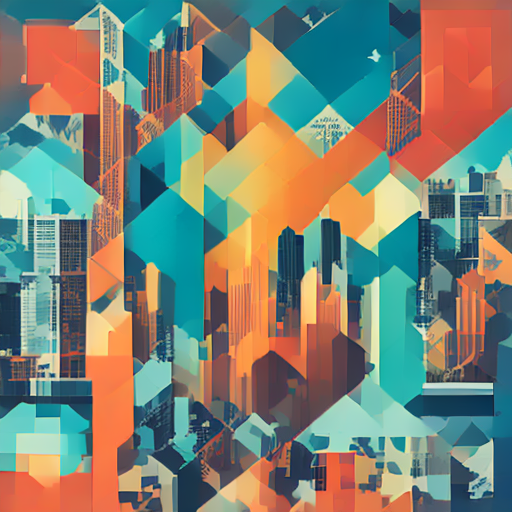

B


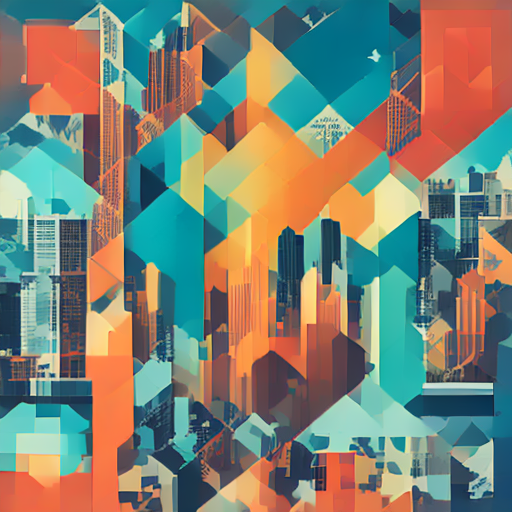

VISUAL_CHECK: True


In [8]:
print("A")
display(image_a)
print("B")
display(image_b)

# Заполните только после фактического просмотра A и B, затем перезапустите эту и последующие ячейки.
VISUAL_CHECK = True
# Пример формата, не результа: VISUAL_CHECK = "PASS: слои силуэта города читаются как отдельные полосы на A и B"
print("VISUAL_CHECK:", VISUAL_CHECK if VISUAL_CHECK is not None else "PENDING")

In [9]:
# Намеренная ошибка: один общий Generator на два вызова. Рабочая реализация не изменяется.
shared_generator = torch.Generator(device="cpu").manual_seed(SEED)
error_image_1 = pipe(
    prompt=PROMPT, num_inference_steps=STEPS, guidance_scale=GUIDANCE,
    height=SIZE, width=SIZE, generator=shared_generator).images[0]
error_image_2 = pipe(
    prompt=PROMPT, num_inference_steps=STEPS, guidance_scale=GUIDANCE,
    height=SIZE, width=SIZE, generator=shared_generator).images[0]
error_sha_1 = L.sha(L.png_bytes(error_image_1))
error_sha_2 = L.sha(L.png_bytes(error_image_2))
error_psnr = L.psnr_db(error_image_1, error_image_2)
intentional_error = {
    "description": "one shared CPU Generator object passed to two consecutive calls",
    "seed": SEED, "sha256_first": error_sha_1, "sha256_second": error_sha_2,
    "pixel_equal": bool(np.array_equal(L.to_arr(error_image_1), L.to_arr(error_image_2))),
    "max_diff": L.max_abs_diff(error_image_1, error_image_2),
    "psnr_db": "inf" if math.isinf(error_psnr) else float(error_psnr),
    "diagnosis": "Generator state advances after the first call",
    "fix": "create a fresh torch.Generator(device='cpu').manual_seed(seed) for each call",
}
(artifacts / "intentional_error.json").write_text(
    json.dumps(intentional_error, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
print(json.dumps(intentional_error, ensure_ascii=False, indent=2))

{
  "description": "one shared CPU Generator object passed to two consecutive calls",
  "seed": 1007,
  "sha256_first": "96b809ceb59215db2a042f58ec1bdf68d336f5b6797a415f70790495fadb6efb",
  "sha256_second": "2c1de397892ed86b7ae10074c54b73f745c2a5e455f918fafe13349c159b55cd",
  "pixel_equal": false,
  "max_diff": 255,
  "psnr_db": 9.035864314461799,
  "diagnosis": "Generator state advances after the first call",
  "fix": "create a fresh torch.Generator(device='cpu').manual_seed(seed) for each call"
}


In [10]:
# Паспорт эксперимента — все измеряемые поля берутся из этого сеанса.
experiment_passport = {
    "status": "COMPLETE" if VISUAL_CHECK is not None else "PARTIAL",
    "variant": VARIANT, "brief": BRIEF, "condition": CONDITION, "seed": SEED,
    "hypothesis": "fresh CPU generators with the same seed and unchanged session will produce bit-identical A and B",
    "tolerance": {"identical": "pixel equality", "close_min_psnr_db": TOLERANCE_DB},
    "model_id": L.MODEL_ID, "revision": L.REVISION, "prompt": PROMPT,
    "parameters": {"steps": STEPS, "guidance_scale": GUIDANCE, "size": SIZE,
                   "generator_device": "cpu", "dtype": "float16"},
    "environment": environment, "library_sha256": library_sha256,
    "timings_seconds": {"load": round(load_seconds, 2), "warmup": round(warmup_seconds, 2),
                            "baseline_generation": round(generation_seconds, 2), "pair": round(pair_seconds, 2)},
    "baseline_sha256": baseline_sha256, "comparison": comparison,
    "visual_check": VISUAL_CHECK, "intentional_error": intentional_error,
    "limitations": [
        "same-session result does not prove reproducibility on another machine",
        "different GPU, package versions or platform may change the result",
        "SHA-256 and PSNR do not assess artistic quality",
    ],
    "license": "Stability AI Community License Agreement; educational non-commercial use; retain required notices when distributing",
}
(artifacts / "passport.json").write_text(
    json.dumps(experiment_passport, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")

environment_lines = [
    "STATUS=ACTUAL", "execution_environment=Google Colab", f"actual_gpu={environment['gpu']}",
    f"python={environment['python']}", f"torch={environment['packages']['torch']}",
    f"diffusers={environment['packages']['diffusers']}", f"transformers={environment['packages']['transformers']}",
    f"pillow={environment['packages']['pillow']}", f"platform={environment['platform']}",
    f"cuda_available={environment['cuda_available']}",
]
(reports / "environment.txt").write_text('\n'.join(environment_lines) + '\n', encoding="utf-8")
print(json.dumps(experiment_passport, ensure_ascii=False, indent=2))

{
  "status": "COMPLETE",
  "variant": 7,
  "brief": 2,
  "condition": "repeat",
  "seed": 1007,
  "hypothesis": "fresh CPU generators with the same seed and unchanged session will produce bit-identical A and B",
  "tolerance": {
    "identical": "pixel equality",
    "close_min_psnr_db": 40.0
  },
  "model_id": "stabilityai/sd-turbo",
  "revision": "b261bac6fd2cf515557d5d0707481eafa0485ec2",
  "prompt": "square podcast cover about the city environment, abstract layered skyline of geometric shapes, teal and orange palette, minimal flat style, no text, no people",
  "parameters": {
    "steps": 1,
    "guidance_scale": 0.0,
    "size": 512,
    "generator_device": "cpu",
    "dtype": "float16"
  },
  "environment": {
    "execution_environment": "Google Colab",
    "gpu": "Tesla T4",
    "cuda_available": true,
    "python": "3.13.15",
    "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
    "packages": {
      "torch": "2.11.0+cu130",
      "diffusers": "0.41.0",
      "transformers

In [11]:
# Итоговая проверка JSON, PNG, SHA-256, структуры и чек-листа методички.
from PIL import Image

required_files = [
    artifacts / "run_001" / "result.png", artifacts / "run_001" / "manifest.json",
    artifacts / "pair_A" / "result.png", artifacts / "pair_A" / "manifest.json",
    artifacts / "pair_B" / "result.png", artifacts / "pair_B" / "manifest.json",
    artifacts / "comparison.json", artifacts / "intentional_error.json",
    artifacts / "passport.json", reports / "environment.txt",
]
for path in required_files:
    assert path.is_file() and path.stat().st_size > 0, f"Missing or empty: {path}"

json_paths = [path for path in required_files if path.suffix == '.json']
loaded_json = {str(path): json.loads(path.read_text(encoding='utf-8')) for path in json_paths}

for path in [artifacts / "run_001" / "result.png", artifacts / "pair_A" / "result.png", artifacts / "pair_B" / "result.png"]:
    with Image.open(path) as check_image:
        check_image.verify()
    with Image.open(path) as check_image:
        assert check_image.format == "PNG" and check_image.size == (512, 512) and check_image.mode == "RGB"

def file_sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

assert file_sha256(artifacts / "run_001" / "result.png") == manifest["sha256"]
assert file_sha256(artifacts / "pair_A" / "result.png") == manifest_a["sha256"] == comparison["sha256_a"]
assert file_sha256(artifacts / "pair_B" / "result.png") == manifest_b["sha256"] == comparison["sha256_b"]
assert all(len(value) == 64 for value in [manifest["sha256"], comparison["sha256_a"], comparison["sha256_b"]])

required_manifest_fields = {"model_id", "revision", "seed", "steps", "guidance_scale", "size",
                            "generator_device", "dtype", "device", "platform", "python",
                            "packages", "image_size", "image_mode", "sha256"}
assert not (required_manifest_fields - set(manifest)), required_manifest_fields - set(manifest)
assert manifest["model_id"] == L.MODEL_ID and manifest["revision"] == L.REVISION
assert manifest["seed"] == 1007 and manifest["steps"] == 1 and manifest["guidance_scale"] == 0.0
assert manifest["size"] == 512 and manifest["generator_device"] == "cpu" and manifest["dtype"] == "float16"
assert comparison["verdict"] in {"identical", "close", "different"}
assert VISUAL_CHECK is not None, "Заполните VISUAL_CHECK после фактического просмотра A/B"
assert experiment_passport["status"] == "COMPLETE"

checklist = {
    "hypothesis_and_tolerance_before_run": True,
    "actual_gpu_and_versions_recorded": True,
    "fixed_model_and_revision": True,
    "baseline_png_and_manifest_valid": True,
    "pair_same_session": True,
    "sha_pixel_maxdiff_psnr_verdict_recorded": True,
    "visual_city_layers_checked": True,
    "shared_generator_error_recorded": True,
    "passport_complete": True,
    "license_and_limitations_recorded": True,
}
print(json.dumps(checklist, ensure_ascii=False, indent=2))
print("FULL CHECKLIST: PASS")

{
  "hypothesis_and_tolerance_before_run": true,
  "actual_gpu_and_versions_recorded": true,
  "fixed_model_and_revision": true,
  "baseline_png_and_manifest_valid": true,
  "pair_same_session": true,
  "sha_pixel_maxdiff_psnr_verdict_recorded": true,
  "visual_city_layers_checked": true,
  "shared_generator_error_recorded": true,
  "passport_complete": true,
  "license_and_limitations_recorded": true
}
FULL CHECKLIST: PASS
